#Imports


In [ ]:
import os
import gc
import glob
import shutil
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
import itertools
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter

#sklearn
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

#tensorflow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img

#treinamentos
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications import EfficientNetB0


#Criando pasta para salvar o dataset e cópia de segurança

In [ ]:
nome_pasta = 'Dataset_Osteoporose'
caminho_pasta = os.path.abspath(nome_pasta) # pasta para salvar o dataset e possiveis alterações
nome_pasta_cp = 'Copia_Dataset'
caminho_copia = os.path.abspath(nome_pasta_cp) # pasta para salvar o dataset sem alterações

if not os.path.exists(nome_pasta):
    os.makedirs(nome_pasta)
    print(f"A pasta '{nome_pasta}' não existia e foi CRIADA com sucesso!")
else:
    print(f"A pasta '{nome_pasta}' JÁ EXISTE.")

if not os.path.exists(nome_pasta_cp):
    os.makedirs(nome_pasta_cp)
    print(f"A pasta '{nome_pasta_cp}' não existia e foi CRIADA com sucesso!\n")
else:
    print(f"A pasta '{nome_pasta_cp}' JÁ EXISTE.\n")

print("Caminho dataset:", caminho_pasta)
print("Caminho cópia dataset:", caminho_copia)

A pasta 'Dataset_Osteoporose' não existia e foi CRIADA com sucesso!
A pasta 'Copia_Dataset' não existia e foi CRIADA com sucesso!

Caminho dataset: /content/Dataset_Osteoporose
Caminho cópia dataset: /content/Copia_Dataset


#Download Dataset

In [ ]:
if not os.listdir(caminho_pasta):
    print("A pasta está vazia. Iniciando o download do dataset...\n")

    # Download do dataset via kagglehub
    path = kagglehub.dataset_download("mohamedgobara/osteoporosis-database")

    # Copia os arquivos baixados para a sua pasta escolhida
    shutil.copytree(path, caminho_pasta, dirs_exist_ok=True)
    print("Download e transferencia para pasta escolhida concluídos com sucesso!\n")
else:
    print(f"A pasta '{caminho_pasta}' já contém arquivos. Download ignorado.\n")

if not os.listdir(caminho_copia):
    print("A pasta está vazia. Iniciando a copia do dataset...\n")
    shutil.copytree(caminho_pasta, caminho_copia, dirs_exist_ok=True) # copiando o dataset
    print("Cópia concluída com sucesso!\n")
else:
    print(f"A pasta '{caminho_copia}' já contém arquivos. Download ignorado.\n")

#  Exibe as informações da pasta
conteudo = os.listdir(caminho_pasta)
conteudo_copia = os.listdir(caminho_copia)
print("------------- Dataset----------------\n")
print("Arquivos salvos em:", caminho_pasta)
print("Conteúdo da pasta:", conteudo)
print("\n------------- Cópia Dataset----------------\n")
print("Arquivos salvos em:", caminho_copia)
print("Conteúdo da pasta:", conteudo_copia)

if conteudo:
    data_dir = os.path.join(caminho_pasta, conteudo[0])
    print("Caminho completo do primeiro item:", data_dir)

A pasta está vazia. Iniciando o download do dataset...



100%|██████████| 182M/182M [00:01<00:00, 107MB/s]

Extracting files...


Download e transferencia para pasta escolhida concluídos com sucesso!

A pasta está vazia. Iniciando a copia do dataset...

Cópia concluída com sucesso!

------------- Dataset----------------

Arquivos salvos em: /content/Dataset_Osteoporose
Conteúdo da pasta: ['Osteoporosis Knee X-ray']

------------- Cópia Dataset----------------

Arquivos salvos em: /content/Copia_Dataset
Conteúdo da pasta: ['Osteoporosis Knee X-ray']
Caminho completo do primeiro item: /content/Dataset_Osteoporose/Osteoporosis Knee X-ray


#Análise Dataset

##Extensões de imagem a serem estudadas

In [ ]:
extensoes_validas = ('.png', '.jpg', '.jpeg')

##Listando pastas e as imagens por cada pasta

In [ ]:
print("Contagem de imagens por pasta:\n -")
classes = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
total_geral = 0

for classe in sorted(classes):
    caminho_classe = os.path.join(data_dir, classe)

    # Conta diretamente os ficheiros físicos da pasta
    imagens = [
        f for f in os.listdir(caminho_classe)
        if os.path.isfile(os.path.join(caminho_classe, f)) and f.lower().endswith(extensoes_validas)
    ]

    qtd = len(imagens)
    total_geral += qtd
    print(f"Classe '{classe}': {qtd} imagens")

print("-")
print(f"Total geral: {total_geral} imagens")

Contagem de imagens por pasta:
 -
Classe 'normal': 36 imagens
Classe 'osteopenia': 154 imagens
Classe 'osteoporosis': 49 imagens
-
Total geral: 239 imagens


##Criando novas imagens para balancear o dataset

###  Definir as transformações para Augmentation (ajustadas para imagens médicas)

In [ ]:
datagen = ImageDataGenerator(
    rotation_range=15,       # Rotação suave de até 15 graus
    width_shift_range=0.05,  # Leve deslocamento horizontal
    height_shift_range=0.05, # Leve deslocamento vertical
    zoom_range=0.05,         # Leve zoom
    horizontal_flip=True,    # Inversão horizontal (útil se a simetria fizer sentido no exame)
    fill_mode='nearest'      # ( Preenche os pixels vazios gerados pelas transformações
                             # repetindo a cor do pixel da borda mais próximo.)
)

###Gerando novas imagens para melhorar o treinamento

In [ ]:
meta_final = 500

for c in sorted(classes):
    caminho_classe = os.path.join(data_dir, c)

    # Função auxiliar para recontar os arquivos físicos na pasta
    def recontar_imagens():
        return [
            f for f in os.listdir(caminho_classe)
            if os.path.isfile(os.path.join(caminho_classe, f)) and f.lower().endswith(extensoes_validas)
        ]

    # Validação contínua até garantir que a meta foi atingida
    while True:
        todos_arquivos = recontar_imagens()
        qtd_atual = len(todos_arquivos)

        # IF / ELSE: Verifica se a meta real no disco foi alcançada
        if qtd_atual >= meta_final:
            print(f"Classe '{c}' já possui {qtd_atual} imagens (meta: {meta_final}). Pulando...")
            break
        else:
            # Filtra as imagens originais para servir de base
            arquivos_originais = [
                os.path.join(caminho_classe, f) for f in todos_arquivos
                if not f.startswith("aug_")
            ]

            if not arquivos_originais:
                arquivos_originais = [os.path.join(caminho_classe, f) for f in todos_arquivos]

            # Verificando se a pasta não esta vazia
            if not arquivos_originais:
                print(f"A pasta '{c}' está completamente vazia. Não é possível gerar imagens.")
                break

            total_faltantes = meta_final - qtd_atual

            # Imprimindo relatório das classes (pastas)
            print(f"\n--- Processando Classe '{c}' ---")
            print(f"Imagens base utilizadas: {len(arquivos_originais)} | Total atual na pasta: {qtd_atual} | Faltam gerar: {total_faltantes}")

            ciclo_imagens = itertools.cycle(arquivos_originais)

            # Barra de progresso para a geração das imagens
            with tqdm(total=total_faltantes, desc=f"Gerando '{c}'", unit="img") as pbar:
                gerados_total = 0
                tamanho_lote = 100

                while gerados_total < total_faltantes:
                    a_gerar_neste_lote = min(tamanho_lote, total_faltantes - gerados_total)
                    gerados_no_lote = 0

                    while gerados_no_lote < a_gerar_neste_lote:
                        img_path = next(ciclo_imagens)

                        img = load_img(img_path)
                        x = img_to_array(img)
                        x = np.expand_dims(x, axis=0)

                        for batch in datagen.flow(
                            x,
                            batch_size=1,
                            save_to_dir=caminho_classe,
                            save_prefix='aug',
                            save_format='png'
                        ):
                            gerados_no_lote += 1
                            gerados_total += 1
                            pbar.update(1)  # Atualiza a barra a cada imagem criada
                            break

                    gc.collect()
                    tf.keras.backend.clear_session()

print("\n✓ Processo concluído com sucesso!")


--- Processando Classe 'normal' ---
Imagens base utilizadas: 36 | Total atual na pasta: 36 | Faltam gerar: 464


Gerando 'normal': 100%|██████████| 464/464 [15:05<00:00,  1.95s/img]



--- Processando Classe 'normal' ---
Imagens base utilizadas: 36 | Total atual na pasta: 492 | Faltam gerar: 8


Gerando 'normal': 100%|██████████| 8/8 [00:12<00:00,  1.53s/img]



--- Processando Classe 'normal' ---
Imagens base utilizadas: 36 | Total atual na pasta: 499 | Faltam gerar: 1


...

Classe 'osteopenia' já possui 500 imagens (meta: 500). Pulando...

--- Processando Classe 'osteoporosis' ---
Imagens base utilizadas: 49 | Total atual na pasta: 49 | Faltam gerar: 451


Gerando 'osteoporosis': 100%|██████████| 451/451 [18:18<00:00,  2.44s/img]



--- Processando Classe 'osteoporosis' ---
Imagens base utilizadas: 49 | Total atual na pasta: 488 | Faltam gerar: 12


Gerando 'osteoporosis': 100%|██████████| 12/12 [00:34<00:00,  2.86s/img]

Classe 'osteoporosis' já possui 500 imagens (meta: 500). Pulando...

✓ Processo concluído com sucesso!


#Separando treino e teste


##70% TREINO ,15% VALIDAÇÃO ,15% TESTE com 25 imagens por lote

In [ ]:
# Arrai para coleta os caminhos dos arquivos e seus indices
filepaths = []
labels = []

classes = sorted(
    [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
)
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

for cls_name in classes:
    caminho_classe = os.path.join(data_dir, cls_name)
    for f in os.listdir(caminho_classe):
        if f.lower().endswith(extensoes_validas):
            filepaths.append(os.path.join(caminho_classe, f))
            labels.append(class_to_idx[cls_name])

filepaths = np.array(filepaths)
labels = np.array(labels)

# 70% Treino e 30% Sobra (Validação + Teste)
X_train, X_temp, y_train, y_temp = train_test_split(
    filepaths, labels, test_size=0.30, random_state=42, stratify=labels
)

# Dividindo os 30% pela metade (15% Validação e 15% Teste)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)



def carregar_imagem_e_label(path, label): # Função que carrega, decodifica e pré-processa uma imagem a partir do caminho e sua classe
    img = tf.io.read_file(path) # Lê o arquivo de imagem do disco como uma string de bytes brutos
    img = tf.image.decode_jpeg(img, channels=3) # Decodifica a imagem JPEG para um tensor numérico com 3 canais de cor (RGB)
    img = tf.image.resize(img, [224, 224]) # Redimensiona a imagem para a dimensão de 224x224 pixels (padrão de muitas redes neurais)
    return img, label # Retorna a imagem pré-processada e seu rótulo correspondente


def criar_dataset(X, y, batch_size=25, shuffle=False): # Função que cria e otimiza o pipeline do dataset no TensorFlow
    dataset = tf.data.Dataset.from_tensor_slices((X, y)) # Cria um objeto Dataset emparelhando a lista de caminhos (X) com suas classes (y)
    if shuffle:                                          # Verifica se deve embaralhar os dados antes do processamento
        dataset = dataset.shuffle(buffer_size=len(X))    # Embaralha a ordem dos dados usando o tamanho do conjunto como limite do buffer
    dataset = dataset.map(carregar_imagem_e_label, num_parallel_calls=tf.data.AUTOTUNE) # Aplica a função de carregamento em paralelo (usando AUTOTUNE para otimizar o uso da CPU)
    dataset = dataset.batch(batch_size) # Agrupa os elementos em lotes (batches) com o tamanho especificado
    return dataset.prefetch(buffer_size=tf.data.AUTOTUNE) # Pré-carrega os próximos lotes na memória em segundo plano para evitar gargalos no treino


# Criação dos conjuntos finais
train_ds = criar_dataset(X_train, y_train, batch_size=25, shuffle=True)
val_ds = criar_dataset(X_val, y_val, batch_size=25, shuffle=False)
test_ds = criar_dataset(X_test, y_test, batch_size=25, shuffle=False)

##Cálculo dos Pesos para Equilibrar as Classes

In [ ]:
train_labels = np.concatenate([y for x, y in train_ds], axis=0)  # Percorre o dataset lote por lote, pega as respostas/classes (y) de cada imagem e junta tudo em uma única lista completa (ex: [1, 1, 0, 2, 1, ...]).

classes_unicas = np.unique(train_labels) # Remove as repetições e entrega apenas os tipos de classes presentes no treino (ex: [0, 1, 2]).

# # Aplica a fórmula do Scikit-Learn para ajustar os pesos de forma inversamente proporcional à frequência de cada classe no conjunto de dados:
# # peso = numero total de amostras / (numeros de classes x numero de amostras por classe)
# # quanto menor a classe maior o peso dela
pesos = compute_class_weight( class_weight="balanced", classes=classes_unicas, y=train_labels)

class_weight_dict = dict(zip(classes_unicas, pesos)) # Passa a lista dos identificadores das classes existentes (por exemplo, [0, 1, 2]).
print("Pesos calculados para cada classe:", class_weight_dict)

data_augmentation = keras.models.Sequential([keras.layers.RandomRotation(0.03), keras.layers.RandomZoom(0.10)]) # Data Augmentation (Evita decorado em poucas imagens)

Pesos calculados para cada classe: {np.int64(0): np.float64(1.0), np.int64(1): np.float64(1.0), np.int64(2): np.float64(1.0)}


##Verificando distribuição das imagens por treinamento, validação e teste

In [ ]:
def contar_classes_porcentagem(dataset, nome_dataset):
    y_totais = []
    for _, labels in dataset: # Percorre todos os lotes do dataset capturando apenas as classes ignorando as imagens
        y_totais.extend(labels.numpy())

    contagem = Counter(y_totais) # Conta quantas vezes cada classe aparece
    total = len(y_totais)# Calcula o total de imagens

    print(f"--- Distribuição no {nome_dataset} ---")
    if total == 0:
        print("Dataset vazio!\n")
        return

    for classe in [0, 1, 2]:
        qtd = contagem[classe] # Obtém a quantidade de imagens da classe
        porcentagem = (qtd / total) * 100 # Calcula a porcentagem da classe
        print(f"Classe {classe}: {qtd} imagens ({porcentagem:.2f}%)") # Exibe quantidade e porcentagem da classe

    print(f"Total: {total} imagens\n")


# Executa a contagem percentual para cada conjunto
contar_classes_porcentagem(train_ds, "Treino (train_ds)")
contar_classes_porcentagem(val_ds, "Validação (val_ds)")
contar_classes_porcentagem(test_ds, "Teste (test_ds)")

--- Distribuição no Treino (train_ds) ---
Classe 0: 350 imagens (33.33%)
Classe 1: 350 imagens (33.33%)
Classe 2: 350 imagens (33.33%)
Total: 1050 imagens

--- Distribuição no Validação (val_ds) ---
Classe 0: 75 imagens (33.33%)
Classe 1: 75 imagens (33.33%)
Classe 2: 75 imagens (33.33%)
Total: 225 imagens

--- Distribuição no Teste (test_ds) ---
Classe 0: 75 imagens (33.33%)
Classe 1: 75 imagens (33.33%)
Classe 2: 75 imagens (33.33%)
Total: 225 imagens



##Verificando canais das imagens antes de iniciar os treinamento
Se as imagens sao monocromaticas apenas preto e branco ou se os 3 canais RGB foram configurados corretamente, importante para definir parametros do treinamento


In [ ]:
for images, labels in train_ds.take(1): # uso o primeiro lote do treinamento para a analise
    print("Formato do lote completo:", images.shape)

Formato do lote completo: (25, 224, 224, 3)


##Imprimindo o primeiro lote das imagens do treinamento

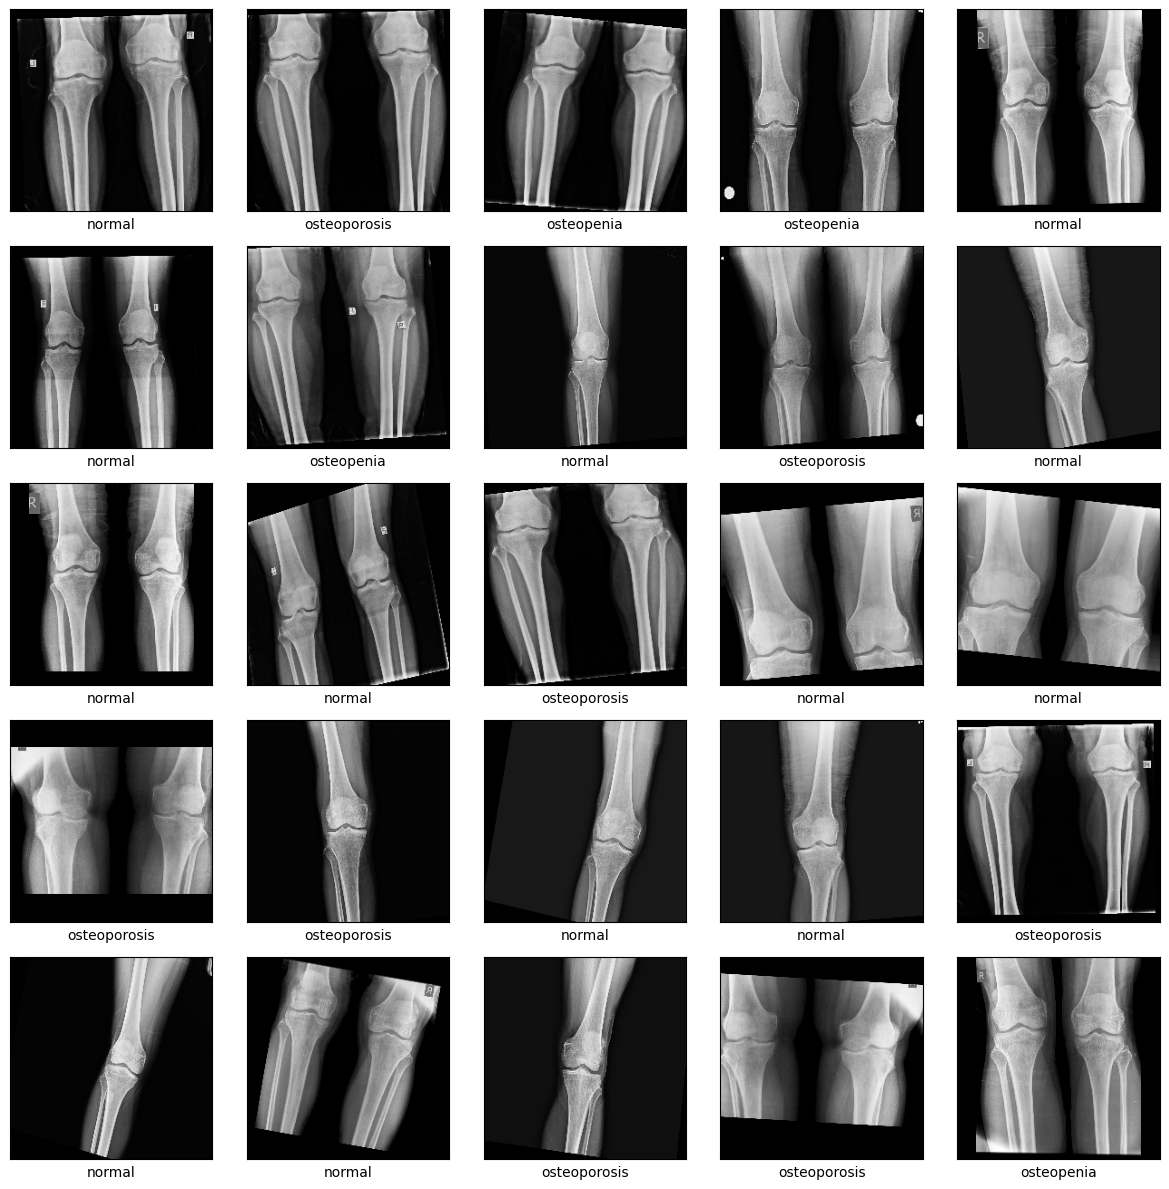

In [ ]:
class_names = ["normal", "osteopenia", "osteoporosis"]  # Desifindo Classes
plt.figure(figsize=(12, 12))  # Tamanho da Imagem a ser impressa

for images, labels in train_ds.take(1):  # Selecionando primeiro Lote
    batch_size = images.shape[0]  # Capturado a quantidade de imagens no lote

    for i in range(batch_size):
        plt.subplot(
            5, 5, i + 1
        )  # numero de linhas , numero de colunas, posição da imagem
        plt.xticks([])  # imagem sem regua
        plt.yticks([])  # imagem sem regua

        img = images[i].numpy()  # Converte o tensor para array numpy

        if (
            img.ndim == 3 and img.shape[-1] == 1
        ):  # Se a imagem tiver formato (H, W, 1), remove a dimensão do canal para ficar (H, W)
            img = img.squeeze(-1)

        img_original = img.astype(
            "uint8"
        )  #  Garante que os valores de 0 a 255 sejam tratados como inteiros uint8
        plt.imshow(
            img_original, vmin=0
        )  # Exibe a imagem enfatizando que qualquer pixel renderizado com o valor 0 sera convertido como preto absoluto
        label_index = int(
            labels[i]
        )  # Seleciona o label da imagem que esta sendo renderizada
        plt.xlabel(
            class_names[label_index]
        )  # imprime o nome da classe de acordo com o indice pre determinado no nome da classe

plt.tight_layout()
plt.show()

#Treinamentos

##MobileNet

In [ ]:
# Definir padrão aleatoriedade no início da iteração
np.random.seed(42)
tf.random.set_seed(42)

# Carregar Treinamento
treino_mobile = MobileNet(
   input_shape=(224, 224, 3),
   weights="imagenet",
   include_top=False,
)

# Congelar quase todas as camadas, exceto os ultimos 26% da rede
treino_mobile.trainable = True
for camada in treino_mobile.layers[:-40]:  # decongelar 26% da rede
  camada.trainable = False

model_mobilenet = tf.keras.models.Sequential(name="Modelo_MobileNetV1")
model_mobilenet.add(tf.keras.layers.Input(shape=(224, 224, 3)))
model_mobilenet.add(tf.keras.layers.Lambda(tf.keras.applications.mobilenet.preprocess_input))
model_mobilenet.add(treino_mobile)
model_mobilenet.add(tf.keras.layers.GlobalAveragePooling2D())
model_mobilenet.add(tf.keras.layers.Dropout(0.3))
model_mobilenet.add(tf.keras.layers.Dense(16, activation="relu"))
model_mobilenet.add(tf.keras.layers.Dropout(0.3))
model_mobilenet.add(tf.keras.layers.Dense(3, activation="softmax"))

model_mobilenet.compile(
  optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
  metrics=["accuracy"],
)

#  Treinamento
history_mobilenet = model_mobilenet.fit(
      train_ds,
      validation_data=val_ds,
      epochs=20,
)

#  Avaliação
print("\n--- Avaliando no conjunto de teste ---")
test_loss_mb, test_acc_mb = model_mobilenet.evaluate(test_ds)
print(f"Acurácia de Teste: {test_acc_mb * 100:.2f}%")

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 228s 5s/step - accuracy: 0.4352 - loss: 1.1658 - val_accuracy: 0.3911 - val_loss: 1.1653
Epoch 2/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 219s 5s/step - accuracy: 0.6257 - loss: 0.8224 - val_accuracy: 0.4667 - val_loss: 1.0324
Epoch 3/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 261s 5s/step - accuracy: 0.6629 - loss: 0.6944 - val_accuracy: 0.5511 - val_loss: 0.8390
Epoch 4/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 193s 5s/step - accuracy: 0.7505 - loss: 0.5642 - val_accuracy: 0.6489 - val_loss: 0.7657
Epoch 5/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 224s 5s/step - accuracy: 0.8067 - loss: 0.4395 - val_accuracy: 0.7867 - val_loss: 0.5584
Epoch 6/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 193s 5s/step - accuracy: 0.8505 - loss: 0.3605 - val_accuracy: 0.7956 - val_loss: 0.4945
Epoch 7/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 219s 5s/step - accuracy: 0.8590 - loss: 0.3177 - val_accuracy: 0.8044 - val_loss: 0.5178
Epoch 8/20
42/42 ━━━━━━━━━━━━━━━━━━━━ 215s 5s/step - accurac

###Avaliação Treinamento

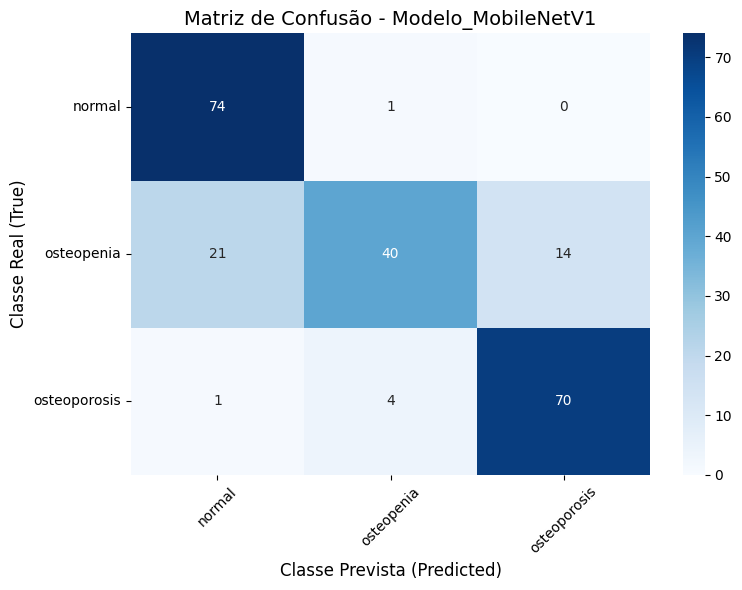


--- Relatório de Classificação: Modelo_MobileNetV1 ---
              precision    recall  f1-score   support

      normal     0.7708    0.9867    0.8655        75
  osteopenia     0.8889    0.5333    0.6667        75
osteoporosis     0.8333    0.9333    0.8805        75

    accuracy                         0.8178       225
   macro avg     0.8310    0.8178    0.8042       225
weighted avg     0.8310    0.8178    0.8042       225



In [ ]:
Avaliação_mobilenet = model_mobilenet

# Extrair os rótulos reais e fazer previsões com alinhamento garantido
y_true_list = []
y_pred_probs_list = []

for x_batch, y_batch in test_ds:
    # Garante a coleta dos rótulos reais do lote
    y_true_list.append(y_batch.numpy())
    # Faz a predição no mesmo lote exato
    probs = Avaliação_mobilenet.predict(x_batch, verbose=0)
    y_pred_probs_list.append(probs)

# Unifica os lotes em vetores 1D/2D
y_true = np.concatenate(y_true_list, axis=0)
y_pred_probs = np.concatenate(y_pred_probs_list, axis=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Obter a lista com os nomes das classes (Garante ordem dos índices)
class_names = [k for k, v in sorted(class_to_idx.items(), key=lambda item: item[1])]

# Matriz de Confusão
cm_mobilenet = confusion_matrix(y_true, y_pred)

# Desenhar o gráfico (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_mobilenet,
    annot=True,  # Mostra os números em cada célula
    fmt="d",  # Formato inteiro
    cmap="Blues",  # Cor do mapa
    xticklabels=class_names,
    yticklabels=class_names,
)

plt.title(f"Matriz de Confusão - {Avaliação_mobilenet.name}", fontsize=14)
plt.ylabel("Classe Real (True)", fontsize=12)
plt.xlabel("Classe Prevista (Predicted)", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Métricas detalhadas por classe
print(f"\n--- Relatório de Classificação: {Avaliação_mobilenet.name} ---")
print(
    classification_report(
        y_true, y_pred, target_names=class_names, digits=4
    )
)

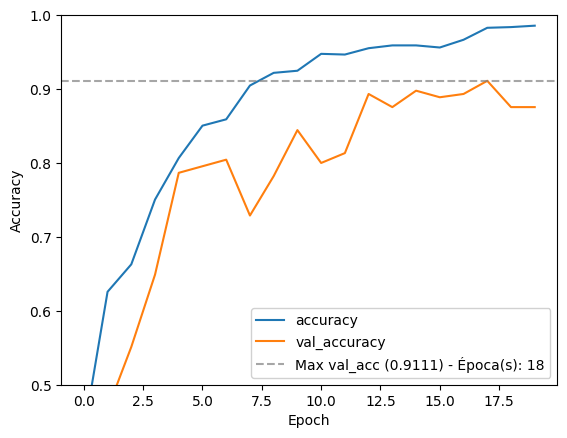

In [ ]:
val_acc_mb = np.array(history_mobilenet.history["val_accuracy"])
acc_mb = history_mobilenet.history["accuracy"]

# Para exibir a contagem de épocas começando em 1:
touch_epochs = [idx + 1 for idx in np.where(np.isclose(val_acc_mb, max_val_acc_mb))[0]]

# Formata a lista de épocas para o texto da legenda
epochs_str = ", ".join(map(str, touch_epochs))

plt.plot(acc_mb, label="accuracy")
plt.plot(val_acc_mb, label="val_accuracy")

# Linha HORIZONTAL tracejada incluindo as épocas de pico na legenda
plt.axhline(
    y=max_val_acc_mb,
    color='gray',
    linestyle='--',
    alpha=0.7,
    label=f'Max val_acc ({max_val_acc_mb:.4f}) - Época(s): {epochs_str}'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim([0.5, 1])

# Legenda com fundo ajustado para não cobrir o gráfico
plt.legend(loc="lower right", framealpha=0.9)
plt.show()

##ResNet

In [ ]:
np.random.seed(42)
tf.random.set_seed(42)

treino_resnet = ResNet50(
   input_shape=(224, 224, 3),
   weights="imagenet",
   include_top=False,
)

treino_resnet.trainable = True
for camada in treino_resnet.layers[:-45]: # decongelar 26% da rede
  camada.trainable = False

model_resnet = tf.keras.models.Sequential(name="Modelo_ResNet50")
model_resnet.add(tf.keras.layers.Input(shape=(224, 224, 3)))
model_resnet.add(tf.keras.layers.Lambda(tf.keras.applications.resnet50.preprocess_input))
model_resnet.add(treino_resnet)
model_resnet.add(tf.keras.layers.GlobalAveragePooling2D())
model_resnet.add(tf.keras.layers.Dropout(0.3))
model_resnet.add(tf.keras.layers.Dense(16, activation="relu"))
model_resnet.add(tf.keras.layers.Dropout(0.3))
model_resnet.add(tf.keras.layers.Dense(3, activation="softmax"))

model_resnet.compile(
  optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
  metrics=["accuracy"],
)

history_resnet = model_resnet.fit(
      train_ds,
      validation_data=val_ds,
      epochs=34,
)

print("\n--- Avaliando no conjunto de teste ---")
test_loss_rn, test_acc_rn = model_resnet.evaluate(test_ds)
print(f"Acurácia de Teste: {test_acc_rn * 100:.2f}%")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/34
42/42 ━━━━━━━━━━━━━━━━━━━━ 502s 11s/step - accuracy: 0.4914 - loss: 1.0558 - val_accuracy: 0.5556 - val_loss: 0.9080
Epoch 2/34
42/42 ━━━━━━━━━━━━━━━━━━━━ 466s 11s/step - accuracy: 0.7162 - loss: 0.6464 - val_accuracy: 0.6844 - val_loss: 0.7716
Epoch 3/34
42/42 ━━━━━━━━━━━━━━━━━━━━ 479s 11s/step - accuracy: 0.8581 - loss: 0.3549 - val_accuracy: 0.7911 - val_loss: 0.7606
Epoch 4/34
42/42 ━━━━━━━━━━━━━━━━━━━━ 488s 11s/step - accuracy: 0.9086 - loss: 0.2293 - val_accuracy: 0.8222 - val_loss: 0.6220
Epoch 5/34
42/42 ━━━━━━━━━━━━━━━━━━━━ 481s 11s/step - accuracy: 0.9467 - loss: 0.1504 - val_accuracy: 0.8089 - val_loss: 1.3328
Epoch 6/34
42/42 ━━━━━━━━━━━━━━━━━━━━ 477s 11s/step - accuracy: 0.9629 - loss: 0.1107 - val_accuracy: 0.8222 - val_loss: 0.6471
Epoch 7/34
42/42 ━━━━━━━━━━━━━━━━━━━━ 446s 11s/step - accuracy: 0.9790 - loss: 0.0830 - val_accuracy: 0.7911 - val_loss: 0.7882
Epoch 8/34
42/42 ━━━━━━━━━━━━━━━━━━━━ 502s 11s/step -

###Avaliação Treinamento

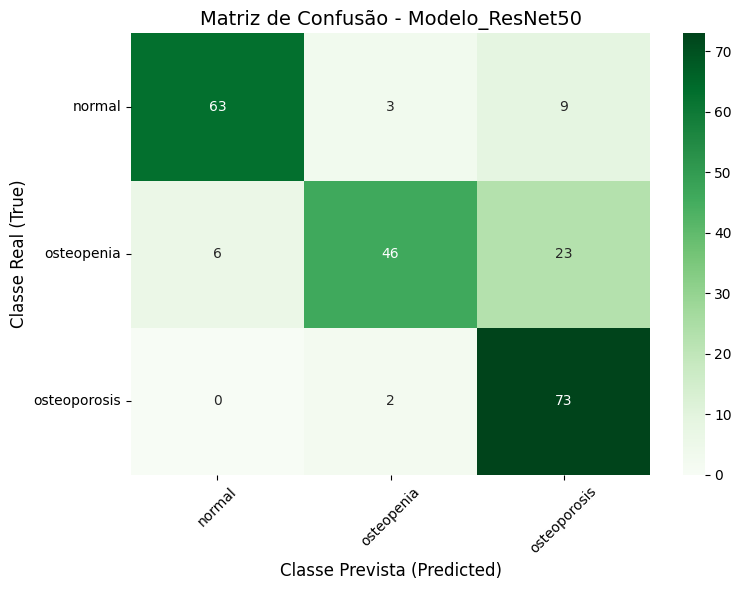


--- Relatório de Classificação: Modelo_ResNet50 ---
              precision    recall  f1-score   support

      normal     0.9130    0.8400    0.8750        75
  osteopenia     0.9020    0.6133    0.7302        75
osteoporosis     0.6952    0.9733    0.8111        75

    accuracy                         0.8089       225
   macro avg     0.8367    0.8089    0.8054       225
weighted avg     0.8367    0.8089    0.8054       225



In [ ]:
Avaliação_resnet = model_resnet

y_true_list = []
y_pred_probs_list = []

for x_batch, y_batch in test_ds:
    y_true_list.append(y_batch.numpy())
    probs = Avaliação_resnet.predict(x_batch, verbose=0)
    y_pred_probs_list.append(probs)

y_true = np.concatenate(y_true_list, axis=0)
y_pred_probs = np.concatenate(y_pred_probs_list, axis=0)
y_pred = np.argmax(y_pred_probs, axis=1)

class_names = [k for k, v in sorted(class_to_idx.items(), key=lambda item: item[1])]
cm_resnet = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names,
)

plt.title(f"Matriz de Confusão - {Avaliação_resnet.name}", fontsize=14)
plt.ylabel("Classe Real (True)", fontsize=12)
plt.xlabel("Classe Prevista (Predicted)", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"\n--- Relatório de Classificação: {Avaliação_resnet.name} ---")
print(
    classification_report(
        y_true, y_pred, target_names=class_names, digits=4
    )
)

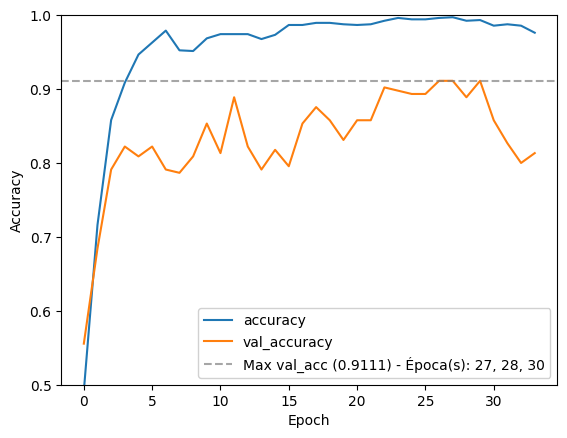

In [ ]:
val_acc_rn = np.array(history_resnet.history["val_accuracy"])
acc_rn = history_resnet.history["accuracy"]

max_val_acc_rn = np.max(val_acc_rn)
touch_epochs = [idx + 1 for idx in np.where(np.isclose(val_acc_rn, max_val_acc_rn))[0]]
epochs_str = ", ".join(map(str, touch_epochs))

plt.plot(acc_rn, label="accuracy")
plt.plot(val_acc_rn, label="val_accuracy")

plt.axhline(
    y=max_val_acc_rn,
    color='gray',
    linestyle='--',
    alpha=0.7,
    label=f'Max val_acc ({max_val_acc_rn:.4f}) - Época(s): {epochs_str}'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim([0.5, 1])

plt.legend(loc="lower right", framealpha=0.9)
plt.show()

##EfficientNet

In [ ]:
tf.keras.backend.clear_session()
gc.collect()

np.random.seed(42)
tf.random.set_seed(42)

treino_efficient = EfficientNetB0(
    input_shape=(224, 224, 3),
    weights="imagenet",
    include_top=False,
)

treino_efficient.trainable = True
for camada in treino_efficient.layers[:-62]:  # decongelar 26% da rede
    camada.trainable = False

model_efficientnet = tf.keras.models.Sequential(name="Modelo_EfficientNetB0")
model_efficientnet.add(tf.keras.layers.Input(shape=(224, 224, 3)))
model_efficientnet.add(treino_efficient)
model_efficientnet.add(tf.keras.layers.GlobalAveragePooling2D())
model_efficientnet.add(tf.keras.layers.Dropout(0.3))
model_efficientnet.add(tf.keras.layers.Dense(16, activation="relu"))
model_efficientnet.add(tf.keras.layers.Dropout(0.3))
model_efficientnet.add(tf.keras.layers.Dense(3, activation="softmax"))

model_efficientnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history_efficientnet = model_efficientnet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=36,
)

test_loss_eff, test_acc_eff = model_efficientnet.evaluate(test_ds)
print(f"Acurácia de Teste EfficientNetB0: {test_acc_eff * 100:.2f}%")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/36
42/42 ━━━━━━━━━━━━━━━━━━━━ 238s 5s/step - accuracy: 0.3914 - loss: 1.0903 - val_accuracy: 0.4267 - val_loss: 1.0429
Epoch 2/36
42/42 ━━━━━━━━━━━━━━━━━━━━ 207s 5s/step - accuracy: 0.5543 - loss: 0.9392 - val_accuracy: 0.6311 - val_loss: 0.8919
Epoch 3/36
42/42 ━━━━━━━━━━━━━━━━━━━━ 200s 5s/step - accuracy: 0.6600 - loss: 0.8015 - val_accuracy: 0.7289 - val_loss: 0.7206
Epoch 4/36
42/42 ━━━━━━━━━━━━━━━━━━━━ 224s 5s/step - accuracy: 0.7362 - loss: 0.6790 - val_accuracy: 0.7956 - val_loss: 0.5816
Epoch 5/36
42/42 ━━━━━━━━━━━━━━━━━━━━ 217s 5s/step - accuracy: 0.7867 - loss: 0.5704 - val_accuracy: 0.8711 - val_loss: 0.4571
Epoch 6/36
42/42 ━━━━━━━━━━━━━━━━━━━━ 212s 5s/step - accuracy: 0.8419 - loss: 0.4561 - val_accuracy: 0.8622 - val_loss: 0.3813
Epoch 7/36
42/42 ━━━━━━━━━━━━━━━━━━━━ 217s 5s/step - accuracy: 0.8705 - loss: 0.3907 - val_accuracy: 0.9200 - val_loss: 0.3190
Epoch 8/36
42/42 ━━━━━━━━━━━━━━━━━━━━ 262s 5s/step - accurac

###Avaliação Treinamento

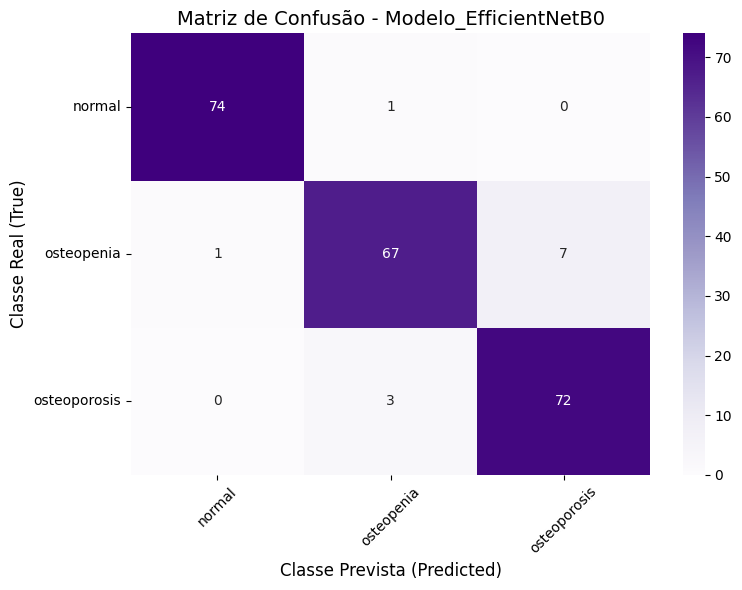


--- Relatório de Classificação: Modelo_EfficientNetB0 ---
              precision    recall  f1-score   support

      normal     0.9867    0.9867    0.9867        75
  osteopenia     0.9437    0.8933    0.9178        75
osteoporosis     0.9114    0.9600    0.9351        75

    accuracy                         0.9467       225
   macro avg     0.9472    0.9467    0.9465       225
weighted avg     0.9472    0.9467    0.9465       225



In [ ]:
Avaliação_efficientnet = model_efficientnet

y_true_list = []
y_pred_probs_list = []

for x_batch, y_batch in test_ds:
    y_true_list.append(y_batch.numpy())
    probs = Avaliação_efficientnet.predict(x_batch, verbose=0)
    y_pred_probs_list.append(probs)

y_true = np.concatenate(y_true_list, axis=0)
y_pred_probs = np.concatenate(y_pred_probs_list, axis=0)
y_pred = np.argmax(y_pred_probs, axis=1)

class_names = [k for k, v in sorted(class_to_idx.items(), key=lambda item: item[1])]

cm_efficientnet = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_efficientnet,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names,
)

plt.title(f"Matriz de Confusão - {Avaliação_efficientnet.name}", fontsize=14)
plt.ylabel("Classe Real (True)", fontsize=12)
plt.xlabel("Classe Prevista (Predicted)", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"\n--- Relatório de Classificação: {Avaliação_efficientnet.name} ---")
print(
    classification_report(
        y_true, y_pred, target_names=class_names, digits=4
    )
)

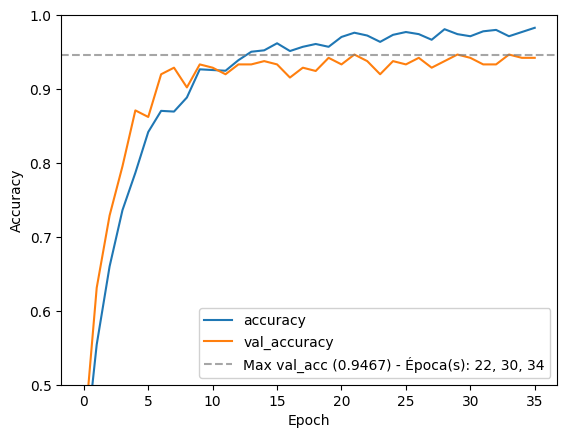

In [ ]:
val_acc_eff = np.array(history_efficientnet.history["val_accuracy"])
acc_eff = history_efficientnet.history["accuracy"]

max_val_acc_eff = np.max(val_acc_eff)
touch_epochs = [idx + 1 for idx in np.where(np.isclose(val_acc_eff, max_val_acc_eff))[0]]
epochs_str = ", ".join(map(str, touch_epochs))

plt.plot(acc_eff, label="accuracy")
plt.plot(val_acc_eff, label="val_accuracy")

plt.axhline(
    y=max_val_acc_eff,
    color='gray',
    linestyle='--',
    alpha=0.7,
    label=f'Max val_acc ({max_val_acc_eff:.4f}) - Época(s): {epochs_str}'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim([0.5, 1])

plt.legend(loc="lower right", framealpha=0.9)
plt.show()

#Comparando Resultados

##Analise dos resultados do modelo

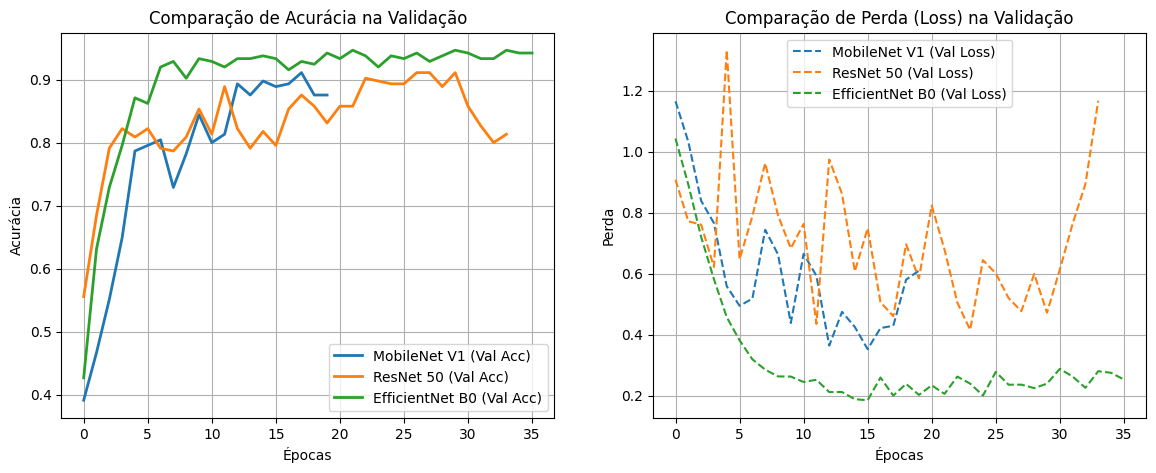

In [ ]:
plt.figure(figsize=(14, 5))

# --- Gráfico de Acurácia de Validação ---
plt.subplot(1, 2, 1)
plt.plot(
    history_mobilenet.history["val_accuracy"],
    label="MobileNet V1 (Val Acc)",
    linewidth=2,
)
plt.plot(
    history_resnet.history["val_accuracy"],
    label="ResNet 50 (Val Acc)",
    linewidth=2,
)
plt.plot(
    history_efficientnet.history["val_accuracy"],
    label="EfficientNet B0 (Val Acc)",
    linewidth=2,
)
plt.title("Comparação de Acurácia na Validação")
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.legend()
plt.grid(True)

# --- Gráfico de Perda (Loss) de Validação ---
plt.subplot(1, 2, 2)
plt.plot(
    history_mobilenet.history["val_loss"],
    label="MobileNet V1 (Val Loss)",
    linestyle="--",
)
plt.plot(
    history_resnet.history["val_loss"],
    label="ResNet 50 (Val Loss)",
    linestyle="--",
)
plt.plot(
    history_efficientnet.history["val_loss"],
    label="EfficientNet B0 (Val Loss)",
    linestyle="--",
)
plt.title("Comparação de Perda (Loss) na Validação")
plt.xlabel("Épocas")
plt.ylabel("Perda")
plt.legend()
plt.grid(True)

plt.show()

##Melhor modelo

In [ ]:
# 1. Monta o DataFrame com os dados de cada modelo
dados_comparativos = {
    "Modelo": ["MobileNet V1", "ResNet 50", "EfficientNet B0"],
    "Acurácia Teste (%)": [
        test_acc_mb * 100,
        test_acc_rn * 100,
        test_acc_eff * 100
    ],
    "Perda (Loss) Teste": [
        test_loss_mb,
        test_loss_rn,
        test_loss_eff
    ]
}

df_comparacao = pd.DataFrame(dados_comparativos)

# 2. Identifica automaticamente o melhor modelo (menor Perda / Loss)
melhor_idx = df_comparacao["Perda (Loss) Teste"].idxmin()
melhor_modelo = df_comparacao.loc[melhor_idx, "Modelo"]
melhor_acc = df_comparacao.loc[melhor_idx, "Acurácia Teste (%)"]
melhor_loss = df_comparacao.loc[melhor_idx, "Perda (Loss) Teste"]

# 3. Formata os valores da tabela para exibição elegante
df_exibicao = df_comparacao.copy()
df_exibicao["Acurácia Teste (%)"] = df_exibicao["Acurácia Teste (%)"].map("{:.4f}%".format)
df_exibicao["Perda (Loss) Teste"] = df_exibicao["Perda (Loss) Teste"].map("{:.4f}".format)

# 4. Imprime os resultados
print("=== TABELA COMPARATIVA ===")
print(df_exibicao.to_string(index=False))
print("\n" + "=")
print(f"🏆 MELHOR MODELO: {melhor_modelo}")
print(f"Acurácia: {melhor_acc:.4f}% | Perda (Loss): {melhor_loss:.4f}")
print("=")

=== TABELA COMPARATIVA ===
         Modelo Acurácia Teste (%) Perda (Loss) Teste
   MobileNet V1           81.7778%             0.7557
      ResNet 50           80.8889%             1.0740
EfficientNet B0           94.6667%             0.2798

=
🏆 MELHOR MODELO: EfficientNet B0
Acurácia: 94.6667% | Perda (Loss): 0.2798
=
